# Data Exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pm4py

Matplotlib is building the font cache; this may take a moment.


  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [3]:
df = pm4py.read_xes('../data/bpic2017.xes')

/Users/maximiliankaiser/tum/bp-pso/tum-bp-pso-process-mining/.venv/lib/python3.12/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(
/Users/maximiliankaiser/tum/bp-pso/tum-bp-pso-process-mining/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 31509/31509 [00:23<00:00, 1327.86it/s]


## 1 Number of Cases
The number of cases in the dataset is determined by counting the unique values in the 'case:concept:name' column of the dataframe.

In [10]:
case_count = df['case:concept:name'].nunique()
case_count

31509

## 2. Number of Events
The number of events in the dataset is determined by counting the total number of rows in the dataframe (Event log)

In [11]:
event_count = df.shape[0]
event_count

1202267

## 3. Number of Process Variants
A process variant is a unique sequence of activities that occur in the process. We can identify the number of process variants by grouping the events by case and then counting the unique sequences of activities.

In [28]:
process_variants = pm4py.get_variants(df)
len(process_variants)

15930

# 4. Number of Distinct Case & Event Attribute labels
Case attributes are properties associated with a case, while event attributes are properties associated with an event and can vary from event to event within the same case. In the dataset, case attributes are prefixed with "case:".

In [13]:
case_attributes = [col for col in df.columns if col.startswith('case:')]
event_attributes = [col for col in df.columns if not col.startswith('case:')]

print(f"Number of distinct case attribute labels: {len(case_attributes)}")
print(f"Number of distinct event attribute labels: {len(event_attributes)}")

Number of distinct case attribute labels: 4
Number of distinct event attribute labels: 15


## Attribute ranges
Further analysis of the ranges of values for each attribute.

In [14]:
id_cols = ['EventID', 'case:concept:name', 'OfferID']

numeric_ranges = []
for col in df.columns:
    s = df[col]
    if col in id_cols:
        continue
    if pd.api.types.is_datetime64_any_dtype(s) or (pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)):
        numeric_ranges.append({'attribute': col, 'min': s.min(), 'max': s.max(), 'missing': s.isna().sum()})

pd.DataFrame(numeric_ranges).set_index('attribute')

for col in df.columns:
    s = df[col]
    if col in id_cols or col in {r['attribute'] for r in numeric_ranges}:
        continue
    counts = s.value_counts()
    print(f"{col}: {len(counts)} variants, {s.isna().sum()} missing")
    for value, n in counts.items():
        print(f"    {value!r}: {n}")
    print()
    
pd.DataFrame(
    [{'attribute': col, 'distinct_values': df[col].nunique(), 'missing': df[col].isna().sum()} for col in id_cols]
).set_index('attribute')

Action: 5 variants, 0 missing
    'statechange': 358940
    'Obtained': 255387
    'Created': 223608
    'Released': 215402
    'Deleted': 148930

org:resource: 149 variants, 0 missing
    'User_1': 148404
    'User_3': 26342
    'User_5': 22900
    'User_87': 22498
    'User_30': 21272
    'User_49': 21134
    'User_123': 20909
    'User_29': 20860
    'User_100': 20651
    'User_2': 19134
    'User_27': 18806
    'User_121': 18726
    'User_28': 18412
    'User_68': 17581
    'User_116': 17423
    'User_10': 16365
    'User_113': 16151
    'User_118': 16005
    'User_75': 15955
    'User_41': 15481
    'User_18': 15432
    'User_126': 14534
    'User_99': 14339
    'User_112': 13949
    'User_46': 13325
    'User_61': 13168
    'User_42': 13045
    'User_117': 13003
    'User_14': 12896
    'User_120': 12726
    'User_15': 12529
    'User_90': 12485
    'User_109': 12330
    'User_16': 12150
    'User_83': 12096
    'User_37': 11857
    'User_40': 11674
    'User_4': 11377
    'User_

,distinct_values,missing
attribute,,
EventID,1202267,0
case:concept:name,31509,0
OfferID,42995,1051413


## 5. Mean & Standard Deviation of Case Lengths
Case length = Number of events in a case

In [20]:
case_event_counts = df.groupby('case:concept:name').size()
mean_case_event_count = case_event_counts.mean()
std_case_event_count = case_event_counts.std()

print(f"Mean number of events per case: {mean_case_event_count:.2f}")
print(f"Standard deviation of events per case: {std_case_event_count:.2f}")

Mean number of events per case: 38.16
Standard deviation of events per case: 16.72


## 6. Mean & Standard Deviation of Case Durations
Case Length = Total time taken for a case to complete: Measure the time difference between the first and last event of each case.

In [31]:
case_start_end_times = df.groupby('case:concept:name')['time:timestamp'].agg(['min', 'max'])
case_start_end_times['case_length'] = (case_start_end_times['max'] - case_start_end_times['min']).dt.total_seconds()
mean_case_length = case_start_end_times['case_length'].mean()
std_case_length = case_start_end_times['case_length'].std()

def format_hours(total_seconds):
    total_seconds = int(total_seconds)
    days, rest = divmod(total_seconds, 86400)
    h, rest = divmod(rest, 3600)
    m, s = divmod(rest, 60)
    return f"{days:02d}d {h:02d}h {m:02d}m {s:02d}s"

print(f"Mean case length: {format_hours(mean_case_length)}")
print(f"Standard deviation of case length: {format_hours(std_case_length)}")

Mean case length: 21d 21h 35m 25s
Standard deviation of case length: 13d 04h 03m 41s


## 7. Addtional Statistics

### 7.1 Case Outcome Distribution
Check the outcome states of the cases. Not the end event, because the end event can differ in each case, but the state is the same.

In [35]:
outcome_activities = pm4py.get_end_activities(df[df['concept:name'].str.startswith('A_')])
outcome_activities

{'A_Pending': 17228,
 'A_Denied': 3752,
 'A_Cancelled': 10431,
 'A_Incomplete': 42,
 'A_Validating': 3,
 'A_Complete': 53}

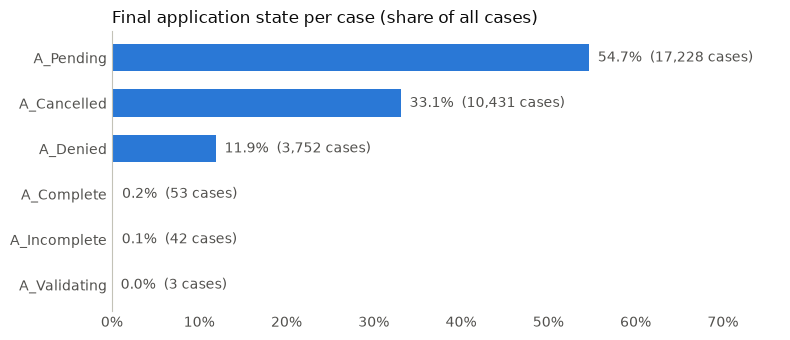

In [36]:
outcome_counts = pd.Series(outcome_activities).sort_values()
outcome_shares = outcome_counts / outcome_counts.sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(outcome_counts.index, outcome_shares, color='#2a78d6', height=0.6)
for bar, share, count in zip(bars, outcome_shares, outcome_counts):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{share:.1%}  ({count:,} cases)", va='center', fontsize=10, color='#52514e')

ax.set_title('Final application state per case (share of all cases)', loc='left', fontsize=12, color='#0b0b0b')
ax.set_xlim(0, outcome_shares.max() * 1.4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.tick_params(colors='#52514e', length=0)
for side in ['top', 'right', 'bottom']:
    ax.spines[side].set_visible(False)
ax.spines['left'].set_color('#c3c2b7')
plt.tight_layout()
plt.show()

### 7.2 Offers per Case
A case can receive several loan offers. The number of offers per case is determined by counting the O_Create Offer events of each case.

In [37]:
offers_per_case = (
    df[df['concept:name'] == 'O_Create Offer']
    .groupby('case:concept:name')
    .size()
    .reindex(df['case:concept:name'].unique(), fill_value=0)
)

print(f"Mean number of offers per case: {offers_per_case.mean():.2f}")
print(f"Standard deviation of offers per case: {offers_per_case.std():.2f}")
print("Distribution of offers per case:")
for n_offers, count in offers_per_case.value_counts().sort_index().items():
    print(f"    {n_offers} offers: {count} cases ({count / len(offers_per_case):.2%})")

Mean number of offers per case: 1.36
Standard deviation of offers per case: 0.71
Distribution of offers per case:
    1 offers: 22950 cases (72.84%)
    2 offers: 6578 cases (20.88%)
    3 offers: 1348 cases (4.28%)
    4 offers: 443 cases (1.41%)
    5 offers: 126 cases (0.40%)
    6 offers: 30 cases (0.10%)
    7 offers: 16 cases (0.05%)
    8 offers: 13 cases (0.04%)
    9 offers: 3 cases (0.01%)
    10 offers: 2 cases (0.01%)
